# Retail Sales Analysis
 
Transaction and campaign-response analysis of a retail customer base.
125,000 transactions, 6,884 customers, May 2011 to March 2015.
 
**Rupsa Chaudhuri**

## Contents
 
1. Data loading and quality checks
2. Customer-level table
3. Distributions
4. Correlation
5. RFM scoring
6. K-means segmentation
7. Customer lifetime value
8. Hypothesis testing
9. Campaign lift
10. Sales over time
11. Purchase cadence
12. Cohort retention analysis
13. Conclusion and limitations

## Analytical note
 
The source file holds one row per **transaction**, but most of the questions
here are about **customers**. Section 2 builds a customer-level table and
everything after it works from that table. Mixing the two grains is the single
easiest way to get a wrong answer in this dataset: a customer with 39 purchases
would otherwise be counted 39 times in any average, test or chart.

## 1. Data loading and quality checks

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.stats import chi2_contingency, f_oneway, kruskal
sns.set(style="whitegrid")
DATA_DIR  = r"D:\Ongoing course\Projects\Retail sales analysis(Internship Studio)\Version 2\Original Dataset"
DATA_START = pd.Timestamp("2011-05-16")  # first day present in the file
DATA_END  = pd.Timestamp("2015-03-16")   # last day in the file, not "today"
HORIZON_M = 12     # CLV horizon in months
PALETTE = {"P0": "#4a90a4", "P1": "#e8a33d", "P2": "#8fbf6f"}

In [2]:
txn  = pd.read_csv(rf"{DATA_DIR}\Retail_Data_Transactions.csv")
resp = pd.read_csv(rf"{DATA_DIR}\Retail_Data_Response.csv")

main_data = txn.merge(resp, on="customer_id", how="left")

print("merged shape:", main_data.shape)
print("\nnulls:\n", main_data.isnull().sum().to_string())

merged shape: (125000, 4)

nulls:
 customer_id     0
trans_date      0
tran_amount     0
response       31


In [3]:
# 31 rows have no response value, belonging to 5 customers absent from the
# response file. 0.02% of rows - dropped.
main_data = main_data.dropna(subset=["response"])
main_data["response"]   = main_data["response"].astype("int64")
main_data["trans_date"] = pd.to_datetime(main_data["trans_date"], format="%d-%b-%y")

print("rows      :", f"{len(main_data):,}")
print("customers :", f"{main_data.customer_id.nunique():,}")
print("revenue   :", f"{main_data.tran_amount.sum():,}")
print("amount    :", f"{main_data.tran_amount.min()} to {main_data.tran_amount.max()}")

rows      : 124,969
customers : 6,884
revenue   : 8,122,378
amount    : 10 to 105


In [4]:
# --- duplicates ---
dupes = main_data.duplicated(["customer_id", "trans_date", "tran_amount"]).sum()
print(f"exact duplicate transactions: {dupes}")

# --- date coverage ---
# Checked before any time-based work, because partial months at either end
# distort every monthly total.
print(f"first transaction: {main_data.trans_date.min().date()}")
print(f"last  transaction: {main_data.trans_date.max().date()}")

monthly_rows = main_data.groupby(main_data.trans_date.dt.to_period("M")).size()
print(f"months covered   : {len(monthly_rows)}")
print(f"first month rows : {monthly_rows.iloc[0]:,}  (16-31 May 2011, 16 days)")
print(f"last  month rows : {monthly_rows.iloc[-1]:,}  (1-16 Mar 2015, 16 days)")
print(f"typical month    : {monthly_rows.iloc[1:-1].median():,.0f}")

exact duplicate transactions: 6
first transaction: 2011-05-16
last  transaction: 2015-03-16
months covered   : 47
first month rows : 1,484  (16-31 May 2011, 16 days)
last  month rows : 1,453  (1-16 Mar 2015, 16 days)
typical month    : 2,729


### Conclusion
 
124,969 usable transactions across 6,884 customers, totalling 8,122,378 in
value. Transaction amounts run 10 to 105 with no values outside that band.
 
Two things to carry forward:
 
- Six transactions are exact duplicates on customer, date and amount. Too few
  to move any figure, but recorded rather than silently dropped.
- **The file opens on 16 May 2011 and closes on 16 March 2015, so the first and
  last months each cover 16 days.** Any monthly total has to be divided by days
  covered before it can be compared with another month. Section 10 depends on
  this entirely.
  
The dataset carries no currency label, so all money figures are unlabelled units.

## 2. Customer-level table
 
One row per customer. Everything from here on is built from this table.

In [5]:
customers = main_data.groupby("customer_id").agg(
    first_purchase = ("trans_date",  "min"),
    last_purchase  = ("trans_date",  "max"),
    frequency      = ("tran_amount", "size"),
    monetary       = ("tran_amount", "sum"),
    aov            = ("tran_amount", "mean"),
    response       = ("response",    "first"),
).reset_index()

# recency and tenure are measured against the END OF THE FILE, not today.
customers["recency_days"] = (DATA_END - customers["last_purchase"]).dt.days
customers["tenure_days"]  = (DATA_END - customers["first_purchase"]).dt.days

print(f"{len(customers):,} customers\n")
print(customers[["frequency", "monetary", "aov",
                 "recency_days", "tenure_days"]].describe().round(2).to_string())

6,884 customers

       frequency  monetary      aov  recency_days  tenure_days
count    6884.00   6884.00  6884.00       6884.00      6884.00
mean       18.15   1179.89    63.09         80.02      1321.49
std         5.18    465.42    12.43         83.25        84.55
min         4.00    149.00    26.70          0.00       506.00
25%        14.00    781.00    52.68         22.00      1294.00
50%        18.00   1228.00    67.71         53.00      1347.50
75%        22.00   1520.25    72.01        111.00      1380.00
max        39.00   2933.00    87.40        678.00      1400.00


### Conclusion
 
6,884 customers. The least active bought 4 times, the most active 39, with a
median of 18. Total spend runs 149 to 2,933 against a median of 1,228.
 
Median recency is 53 days and the maximum is 678, so almost nobody in this base
has stopped buying outright. That matters for how recency is used later: a
cutoff of several hundred days would place nearly the whole base in one bucket.
 
`aov` is carried as its own column because total spend and purchase count are
nearly the same signal here, while basket size is a separate question.

## 3. Distributions

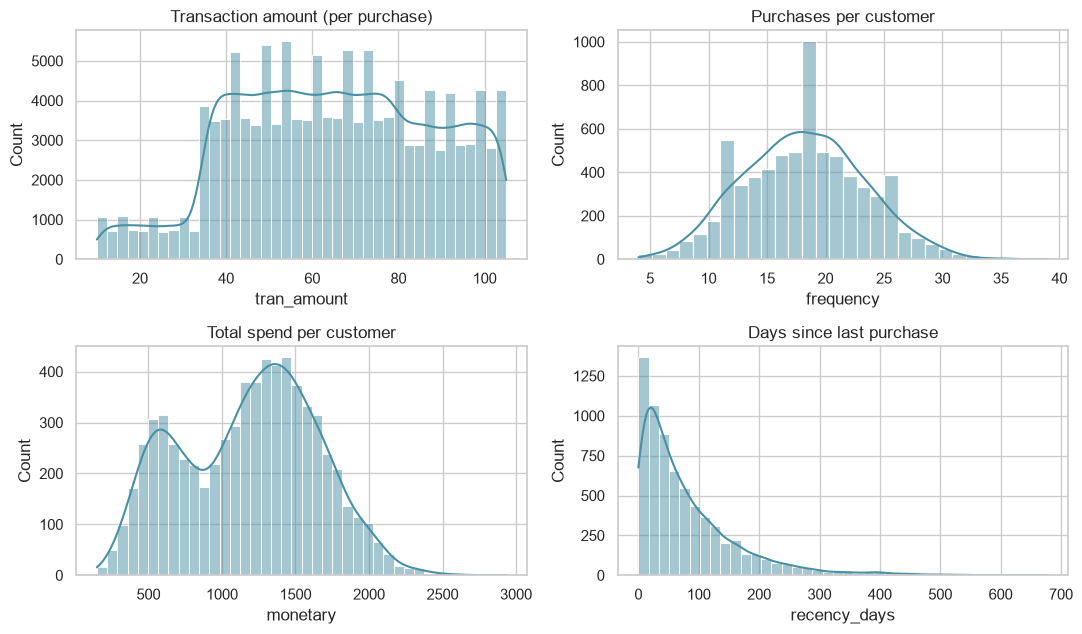

campaign response: 647 of 6,884 customers = 9.40%


In [6]:
fig, ax = plt.subplots(2, 2, figsize=(11, 6.5))

sns.histplot(main_data["tran_amount"], bins=40, kde=True, ax=ax[0, 0], color="#4a90a4")
ax[0, 0].set_title("Transaction amount (per purchase)")

sns.histplot(customers["frequency"], bins=30, kde=True, ax=ax[0, 1], color="#4a90a4")
ax[0, 1].set_title("Purchases per customer")

sns.histplot(customers["monetary"], bins=40, kde=True, ax=ax[1, 0], color="#4a90a4")
ax[1, 0].set_title("Total spend per customer")

sns.histplot(customers["recency_days"], bins=40, kde=True, ax=ax[1, 1], color="#4a90a4")
ax[1, 1].set_title("Days since last purchase")

plt.tight_layout(); plt.show()

print(f"campaign response: {customers.response.sum():,} of {len(customers):,} "
      f"customers = {customers.response.mean():.2%}")

### Conclusion
 
Transaction amounts are close to uniform between roughly 40 and 100, with a
thinner tail below 40. There is no normal-shaped centre and no high-value
outlier tail, which is unusual for retail spend.
 
Purchase counts are roughly symmetric around 18.
 
**Total spend is bimodal, and that is not two customer types.** It is what a
broad spread of purchase counts produces once multiplied by a basket size that
barely varies. Reading two segments off this histogram would be an artefact of
the arithmetic, so segmentation is done properly in Section 6 instead.
 
Recency is heavily concentrated below 150 days. 9.40% of customers responded to
the campaign. That figure is per customer; computed across transaction rows it
would come out at 11.08%, because customers who respond also buy more often.

## 4. Correlation
 
Some pairs here are arithmetic rather than findings: `monetary` sums the amounts
that `frequency` counts, and `aov` is `monetary` divided by `frequency`. Those
cannot come out any other way and are labelled as such below.

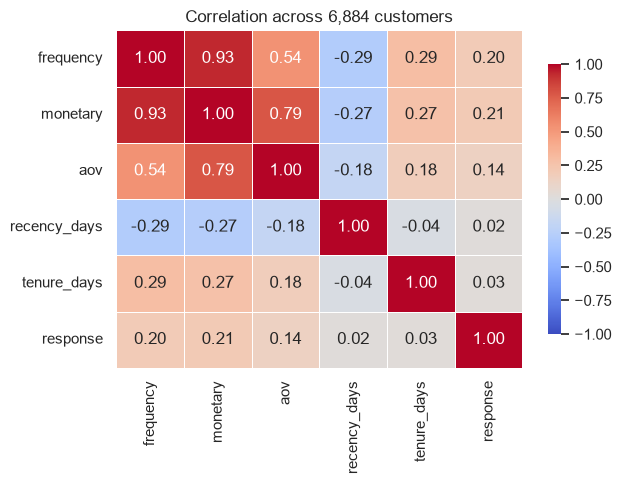

definitional:
  frequency x monetary  +0.934
  monetary  x aov       +0.787
informative:
  frequency    x aov           +0.536
  frequency    x recency_days  -0.286
  frequency    x response      +0.201
  tenure_days  x frequency     +0.292


In [7]:
corr_cols = ["frequency", "monetary", "aov", "recency_days", "tenure_days", "response"]
corr = customers[corr_cols].corr()

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Correlation across 6,884 customers")
plt.tight_layout(); plt.show()

print("definitional:")
print(f"  frequency x monetary  {corr.loc['frequency','monetary']:+.3f}")
print(f"  monetary  x aov       {corr.loc['monetary','aov']:+.3f}")
print("informative:")
for a, b in [("frequency","aov"), ("frequency","recency_days"),
             ("frequency","response"), ("tenure_days","frequency")]:
    print(f"  {a:12} x {b:13} {corr.loc[a,b]:+.3f}")

### Conclusion
 
The one correlation that carries information is **frequency against average
order value at 0.536**. Customers who buy more often also spend more per visit.
Nothing in the arithmetic forced that, frequent buyers could just as easily
have had smaller baskets, so it is a real property of this base.
 
Frequency against recency is −0.286: frequent buyers have bought more recently,
as expected.
 
Response correlates weakly with frequency (0.201) and total spend (0.206), and
not at all with recency (0.023). Section 5 looks at recency and response more
carefully, because that near-zero figure hides something.
 
**Tenure against frequency is 0.292**, meaning customers who appear earlier in
the file buy more often. On observed data that would suggest early customers are
more valuable. Here it more likely reflects the observation window, since a
high-frequency customer shows up sooner simply by buying sooner. Section 12
returns to this.

## 5. RFM scoring
 
Each customer scored 1 to 5 on recency, frequency and monetary by quintile,
recency reversed so that a recent purchase scores 5.
 
Quintiles rather than fixed thresholds, because quintiles adapt to the
distribution. Given that median recency is 53 days, any cutoff set in the
hundreds of days would put almost the whole base into a single bucket.

In [8]:
# .rank(method="first") breaks ties before cutting. frequency is a small integer
# with thousands of customers sharing each value, and plain qcut fails on it.
customers["R"] = pd.qcut(customers.recency_days, 5, labels=[5, 4, 3, 2, 1]).astype(int)
customers["F"] = pd.qcut(customers.frequency.rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
customers["M"] = pd.qcut(customers.monetary.rank(method="first"),  5, labels=[1,2,3,4,5]).astype(int)

customers["RFM_score"] = (customers.R.astype(str)
                          + customers.F.astype(str)
                          + customers.M.astype(str))
customers["RFM_total"] = customers.R + customers.F + customers.M

def rfm_tier(row):
    if row.R >= 4 and row.F >= 4: return "Champions"
    if row.R >= 3 and row.F >= 3: return "Loyal"
    if row.R >= 4 and row.F <= 2: return "New / Promising"
    if row.R <= 2 and row.F >= 4: return "At Risk"
    if row.R <= 2 and row.F <= 2: return "Hibernating"
    return "Needs Attention"

customers["rfm_tier"] = customers.apply(rfm_tier, axis=1)

tiers = customers.groupby("rfm_tier").agg(
    customers_n   = ("customer_id", "size"),
    avg_monetary  = ("monetary", "mean"),
    revenue       = ("monetary", "sum"),
    response_rate = ("response", "mean"),
).sort_values("revenue", ascending=False)
tiers["pct_base"]      = (tiers.customers_n / len(customers) * 100).round(1)
tiers["pct_revenue"]   = (tiers.revenue / customers.monetary.sum() * 100).round(1)
tiers["response_rate"] = (tiers.response_rate * 100).round(2)
print(tiers.round(2).to_string())

                 customers_n  avg_monetary  revenue  response_rate  pct_base  pct_revenue
rfm_tier                                                                                 
Champions               1339       1626.94  2178469          11.58      19.5         26.8
Loyal                   1420       1373.51  1950384          10.56      20.6         24.0
At Risk                  807       1580.99  1275855          23.17      11.7         15.7
Needs Attention         1069        988.21  1056398           7.30      15.5         13.0
Hibernating             1361        713.31   970817           4.85      19.8         12.0
New / Promising          888        777.54   690455           1.24      12.9          8.5


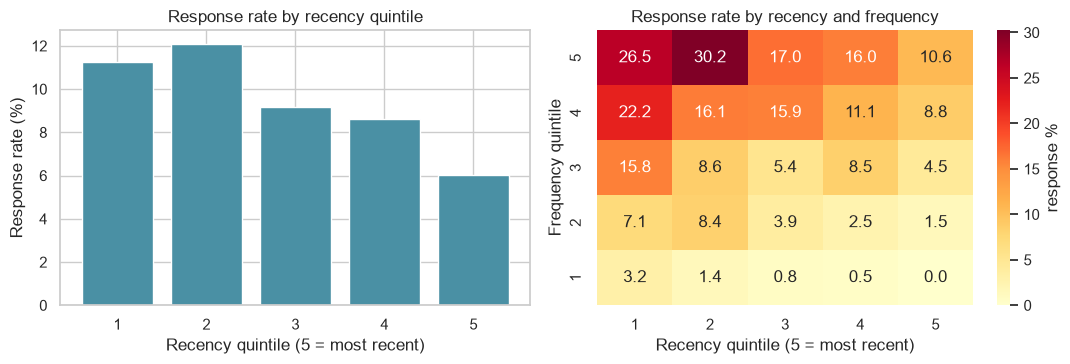

response rate by recency quintile (5 = most recent):
R
1    11.25
2    12.11
3     9.17
4     8.63
5     6.02

response rate by frequency quintile (5 = most frequent):
F
1     1.60
2     4.87
3     8.43
4    14.02
5    18.08


In [9]:
# Does recency behave the way RFM practice assumes?
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

r_resp = customers.groupby("R").response.mean() * 100
ax[0].bar(r_resp.index, r_resp.values, color="#4a90a4")
ax[0].set_xlabel("Recency quintile (5 = most recent)")
ax[0].set_ylabel("Response rate (%)")
ax[0].set_title("Response rate by recency quintile")

piv = pd.crosstab(customers.F, customers.R, values=customers.response, aggfunc="mean") * 100
sns.heatmap(piv, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax[1],
            cbar_kws={"label": "response %"})
ax[1].set_xlabel("Recency quintile (5 = most recent)")
ax[1].set_ylabel("Frequency quintile")
ax[1].invert_yaxis()
ax[1].set_title("Response rate by recency and frequency")

plt.tight_layout(); plt.show()

print("response rate by recency quintile (5 = most recent):")
print((customers.groupby("R").response.mean() * 100).round(2).to_string())
print("\nresponse rate by frequency quintile (5 = most frequent):")
print((customers.groupby("F").response.mean() * 100).round(2).to_string())

### Conclusion
 
Champions and Loyal together are 40% of the base and just over half of revenue.
Hibernating is a fifth of the base and 12% of revenue.
 
**Recency runs backwards against campaign response in this dataset.** The least
recent quintile responds at 11.25% and the most recent at 6.02%. Holding
frequency at its top quintile the gap is wider still, 26.5% against 10.6%.
 
That is why *At Risk* carries the highest response rate of any tier at 23.17%,
ahead of Champions at 11.58%. Standard RFM practice assumes the opposite
ordering, so this is reported as a property of this particular dataset rather
than as a general finding. It also explains the near-zero recency-to-response
correlation in Section 4: the relationship exists, it just points the wrong way
and partially cancels against the frequency effect.
 
Frequency is the dimension that actually separates response here, running from
1.60% in the bottom quintile to 18.08% in the top.
 

## 6. K-means segmentation
 
Clustering on standardised frequency and monetary, fitted on the customer table.

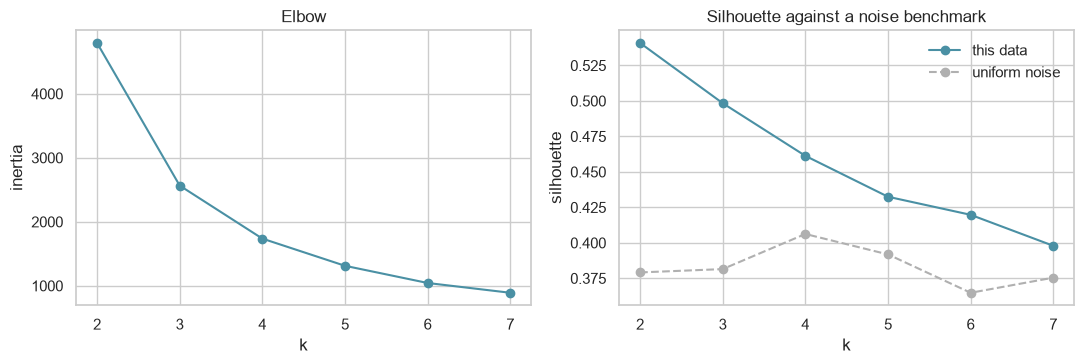

 k  inertia  silhouette  silhouette_noise
 2 4794.125       0.541             0.379
 3 2565.411       0.498             0.382
 4 1737.058       0.461             0.406
 5 1312.359       0.432             0.392
 6 1043.678       0.420             0.365
 7  890.869       0.398             0.375

corr(frequency, monetary) = 0.934
PC1 explains 96.7% of variance


In [10]:
X = StandardScaler().fit_transform(customers[["frequency", "monetary"]])

scores = []
for k in range(2, 8):
    km_k = KMeans(n_clusters=k, n_init=25, random_state=42).fit(X)
    scores.append((k, km_k.inertia_, silhouette_score(X, km_k.labels_)))
scores = pd.DataFrame(scores, columns=["k", "inertia", "silhouette"])

# Benchmark: the same scores on structureless uniform noise over the same range.
rng = np.random.default_rng(42)
noise = rng.uniform(X.min(axis=0), X.max(axis=0), size=X.shape)
scores["silhouette_noise"] = [
    silhouette_score(noise, KMeans(n_clusters=k, n_init=25, random_state=42).fit_predict(noise))
    for k in scores.k]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(scores.k, scores.inertia, marker="o", color="#4a90a4")
ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia"); ax[0].set_title("Elbow")

ax[1].plot(scores.k, scores.silhouette, marker="o", color="#4a90a4", label="this data")
ax[1].plot(scores.k, scores.silhouette_noise, marker="o", ls="--",
           color="#b0b0b0", label="uniform noise")
ax[1].set_xlabel("k"); ax[1].set_ylabel("silhouette")
ax[1].set_title("Silhouette against a noise benchmark"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

print(scores.round(3).to_string(index=False))
print(f"\ncorr(frequency, monetary) = {customers.frequency.corr(customers.monetary):.3f}")

from sklearn.decomposition import PCA
pca = PCA().fit(X)
print(f"PC1 explains {pca.explained_variance_ratio_[0]:.1%} of variance")

### Conclusion on choosing k
 
**There is no natural cluster structure in this data, and the diagnostics say so
plainly.**
 
- Silhouette falls monotonically from k=2 (0.541) to k=7 (0.398). No peak.
- The elbow curve bends smoothly with no distinct corner.
- Frequency and monetary correlate at 0.93, and the first principal component
  carries 96.7% of the variance. The customers lie along a line.
- Against uniform noise over the same range, silhouette scores 0.38 to 0.41.
  This data manages 0.46 to 0.54 — better, but not by the margin real clusters
  would produce.
  
So k-means here is **banding a continuum, not discovering groups**. k=3 is
chosen because three tiers is a workable convention and lines up with the RFM
tiers, and the limitation is stated rather than hidden behind an elbow plot that
does not bend.

In [11]:
kmeans = KMeans(n_clusters=3, n_init=25, random_state=42).fit(X)
customers["cluster"] = kmeans.labels_

# Label by mean spend, so P0 is always the top tier whatever ids sklearn assigns.
order = customers.groupby("cluster")["monetary"].mean().sort_values(ascending=False).index
customers["segment"] = customers["cluster"].map({c: f"P{i}" for i, c in enumerate(order)})

segments = customers.groupby("segment").agg(
    customers_n   = ("customer_id", "size"),
    avg_frequency = ("frequency", "mean"),
    avg_aov       = ("aov", "mean"),
    avg_monetary  = ("monetary", "mean"),
    revenue       = ("monetary", "sum"),
    avg_recency   = ("recency_days", "mean"),
    response_rate = ("response", "mean"),
)
segments["pct_base"]      = (segments.customers_n / len(customers) * 100).round(1)
segments["pct_revenue"]   = (segments.revenue / customers.monetary.sum() * 100).round(1)
segments["response_rate"] = (segments.response_rate * 100).round(2)
print(segments.round(2).to_string())

         customers_n  avg_frequency  avg_aov  avg_monetary  revenue  avg_recency  response_rate  pct_base  pct_revenue
segment                                                                                                               
P0              1904          24.45    70.76       1728.28  3290641        55.14          17.28      27.7         40.5
P1              2906          18.19    67.61       1226.01  3562799        74.67           9.39      42.2         43.9
P2              2074          12.32    49.73        611.83  1268938       110.37           2.17      30.1         15.6


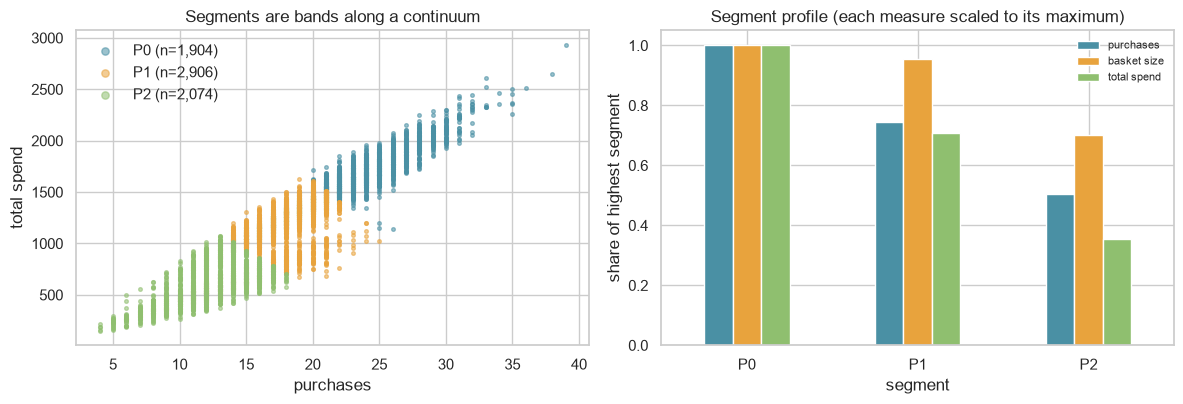

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

for s in ["P0", "P1", "P2"]:
    sub = customers[customers.segment == s]
    ax[0].scatter(sub.frequency, sub.monetary, s=7, alpha=.55,
                  color=PALETTE[s], label=f"{s} (n={len(sub):,})")
ax[0].set_xlabel("purchases"); ax[0].set_ylabel("total spend")
ax[0].set_title("Segments are bands along a continuum")
ax[0].legend(frameon=False, markerscale=2)

prof = segments[["avg_frequency", "avg_aov", "avg_monetary"]].copy()
prof = prof / prof.max()          # scaled to a common axis for shape comparison
prof.plot(kind="bar", ax=ax[1], rot=0,
          color=["#4a90a4", "#e8a33d", "#8fbf6f"])
ax[1].set_title("Segment profile (each measure scaled to its maximum)")
ax[1].set_ylabel("share of highest segment")
ax[1].legend(["purchases", "basket size", "total spend"], frameon=False, fontsize=8)

plt.tight_layout(); plt.show()

### Conclusion
 
| Segment | Customers | % of base | Purchases | Basket | Total spend | % of revenue |
|---|---|---|---|---|---|---|
| P0 | 1,904 | 27.7% | 24.45 | 70.76 | 1,728.28 | 40.5% |
| P1 | 2,906 | 42.2% | 18.19 | 67.61 | 1,226.01 | 43.9% |
| P2 | 2,074 | 30.1% | 12.32 | 49.73 | 611.83 | 15.6% |
 
P0 is 27.7% of customers and 40.5% of revenue. P2 is 30.1% of customers and
15.6% of revenue.
 
The scatter plot is the honest picture: the bands are cuts across a single
diagonal cloud, with no gaps between them. The profile chart shows P0 and P1
differ mainly in how often they buy rather than in basket size, while P2 is
lower on both.
 
Read the segments as a value ranking, which they are, rather than as three
distinct customer types, which they are not.
 

## 7. Customer lifetime value
 
Average order value multiplied by the customer's own observed monthly purchase
rate, projected over 12 months. No churn term, so the estimate assumes a
customer continues at their observed rate.
 

In [13]:
customers["months_observed"]     = (customers["tenure_days"] / 30.44).clip(lower=1)
customers["purchases_per_month"] = customers["frequency"] / customers["months_observed"]
customers["clv_12m"]             = (customers["aov"]
                                    * customers["purchases_per_month"]
                                    * HORIZON_M)

# Sanity check. A forward estimate on a flat business should land near one
# year of observed revenue.
last_12m = main_data.loc[
    main_data.trans_date >= DATA_END - pd.DateOffset(months=12), "tran_amount"].sum()
print(f"projected 12-month value : {customers.clv_12m.sum():,.0f}")
print(f"observed final 12 months : {last_12m:,}")
print(f"ratio                    : {customers.clv_12m.sum()/last_12m:.2f}")

print("\n", customers.groupby("segment").clv_12m.agg(["mean", "sum"]).round(2).to_string())

projected 12-month value : 2,237,678
observed final 12 months : 2,108,426
ratio                    : 1.06

            mean        sum
segment                   
P0       469.67  894249.78
P1       338.20  982808.02
P2       173.88  360620.22


### Conclusion
 
Projected 12-month value across the base is 2,237,678 against 2,108,426 of
revenue actually recorded in the final twelve months. A ratio of 1.06, which is
what a forward estimate should produce on a business showing no growth or
decline.
 
Mean 12-month value is 325.05, ranging from 43.95 to 770.21. By segment: P0
469.67, P1 338.20, P2 173.88.
 
P1 holds the largest total at 982,808 because it is the largest group, while P0
has the highest value per customer. Both facts matter, and they point at
different decisions: P0 for per-customer investment, P1 for aggregate revenue
protection.
 
The sanity check above is the part worth keeping as a habit. Any derived metric
should be compared against something already known before it is reported.

## 8. Hypothesis testing
 
Both tests run on 6,884 customers. At that size a p-value approaches zero for
almost any real effect, so an effect size is reported alongside each.

In [14]:
# --- segment against campaign response ---
ct = pd.crosstab(customers["segment"], customers["response"])
chi2, p, dof, expected = chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

print("H0: customer segment and campaign response are independent\n")
print(ct.to_string())
print(f"\nchi-square {chi2:.2f}   dof {dof}   p {p:.3e}   n {n:,}")
print(f"Cramer's V {cramers_v:.3f}   (0.1 weak, 0.3 moderate, 0.5 strong)")

H0: customer segment and campaign response are independent

response     0    1
segment            
P0        1575  329
P1        2633  273
P2        2029   45

chi-square 266.15   dof 2   p 1.609e-58   n 6,884
Cramer's V 0.197   (0.1 weak, 0.3 moderate, 0.5 strong)


In [15]:
# --- segment against recency ---
# Recency is used here rather than transaction amount. The segments were built
# from frequency and monetary, and monetary is the sum of transaction amounts,
# so testing transaction amount against segment would compare the clustering
# against its own input. Recency took no part in the clustering.
groups = [customers.loc[customers.segment == s, "recency_days"] for s in ["P0", "P1", "P2"]]
F, p_anova = f_oneway(*groups)

grand = customers["recency_days"].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
eta_sq = ss_between / ((customers["recency_days"] - grand) ** 2).sum()

H, p_kw = kruskal(*groups)

print("H0: mean recency is equal across segments\n")
print(customers.groupby("segment").recency_days.agg(["mean", "median", "std"]).round(1).to_string())
print(f"\nANOVA F {F:.2f}   p {p_anova:.3e}   eta-squared {eta_sq:.3f}")
print(f"Kruskal-Wallis H {H:.2f}   p {p_kw:.3e}   (no normality assumption)")

H0: mean recency is equal across segments

          mean  median    std
segment                      
P0        55.1    39.0   53.8
P1        74.7    53.0   71.6
P2       110.4    77.0  107.9

ANOVA F 245.04   p 1.577e-103   eta-squared 0.066
Kruskal-Wallis H 331.52   p 1.027e-72   (no normality assumption)


### Conclusion
 
**Segment and campaign response are related, modestly.** Chi-square 266.15 on 2
degrees of freedom, p ≈ 1.6e-58, Cramér's V 0.197. The association is real but
weak-to-moderate, and V is the number worth quoting rather than the p-value.
Response rates run 17.28% in P0, 9.39% in P1 and 2.17% in P2.
 
**Segments differ in recency**, with P0 at 55 days since last purchase, P1 at 75
and P2 at 110. F = 245.04 with η² = 0.066, so segment accounts for about 7% of
the variance in recency. Kruskal-Wallis agrees, which matters because recency is
right-skewed and ANOVA's normality assumption does not strictly hold.
 
An effect size is reported with each test because at n = 6,884 statistical
significance is nearly guaranteed and says little on its own. η² of 0.066 is a
genuine but small effect, and describing it that way is more useful than calling
it significant.

## 9. Campaign lift
 
The response flag is the only outcome variable in this dataset. This section
asks what it would be worth to target with it.

In [16]:
base_rate = customers.response.mean()

lift = customers.groupby("segment").agg(
    customers_n = ("customer_id", "size"),
    responders  = ("response", "sum"),
    resp_rate   = ("response", "mean"),
)
lift["pct_of_base"]       = (lift.customers_n / len(customers) * 100).round(1)
lift["pct_of_responders"] = (lift.responders / customers.response.sum() * 100).round(1)
lift["lift"]              = (lift.resp_rate / base_rate).round(2)
lift["resp_rate"]         = (lift.resp_rate * 100).round(2)

print(f"base response rate: {base_rate:.2%} "
      f"({customers.response.sum():,} of {len(customers):,})\n")
print(lift.to_string())

base response rate: 9.40% (647 of 6,884)

         customers_n  responders  resp_rate  pct_of_base  pct_of_responders  lift
segment                                                                          
P0              1904         329      17.28         27.7               50.9  1.84
P1              2906         273       9.39         42.2               42.2  1.00
P2              2074          45       2.17         30.1                7.0  0.23


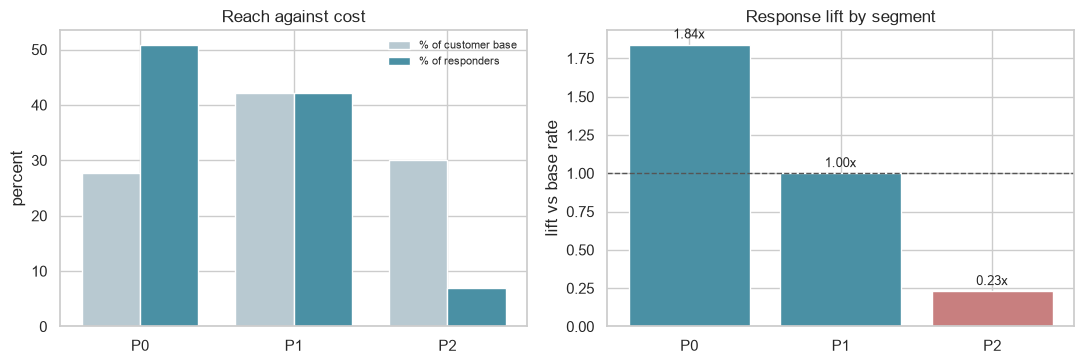

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

x = np.arange(3); w = 0.38
ax[0].bar(x - w/2, lift.pct_of_base, w, label="% of customer base", color="#b8c9d1")
ax[0].bar(x + w/2, lift.pct_of_responders, w, label="% of responders", color="#4a90a4")
ax[0].set_xticks(x); ax[0].set_xticklabels(lift.index)
ax[0].set_ylabel("percent"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("Reach against cost")

colors = ["#4a90a4" if v >= 1 else "#c87f7f" for v in lift.lift]
ax[1].bar(lift.index, lift.lift, color=colors)
ax[1].axhline(1.0, color="#555", ls="--", lw=1)
ax[1].set_ylabel("lift vs base rate"); ax[1].set_title("Response lift by segment")
for i, v in enumerate(lift.lift):
    ax[1].text(i, v + .04, f"{v:.2f}x", ha="center", fontsize=9)

plt.tight_layout(); plt.show()

### Conclusion
 
This is the one section that carries a decision.
 
**P0 is 27.7% of the customer base and holds 50.9% of all responders**, a lift of
1.84x. A campaign restricted to P0 reaches half the responders while contacting
roughly a quarter of the base.
 
**P2 is 30.1% of the base and 7.0% of responders**, a lift of 0.23x. At equal
cost per contact this segment returns less than a quarter of the average, so
including it in a broad mailing destroys value.
 
P1 sits exactly at the base rate, 1.00x, which makes it the marginal group:
worth contacting only once P0 is exhausted and the cost per contact is known.
 
The response flag carries no date, so it records whether a customer ever
responded and cannot be attributed to a specific campaign or tracked over time.
Any statement about campaign performance changing across years would be reading
a trend into a static variable.

## 10. Sales over time
 
Monthly totals are divided by the number of days each month contributes, because
the first and last months of the file cover 16 days each and February is short.

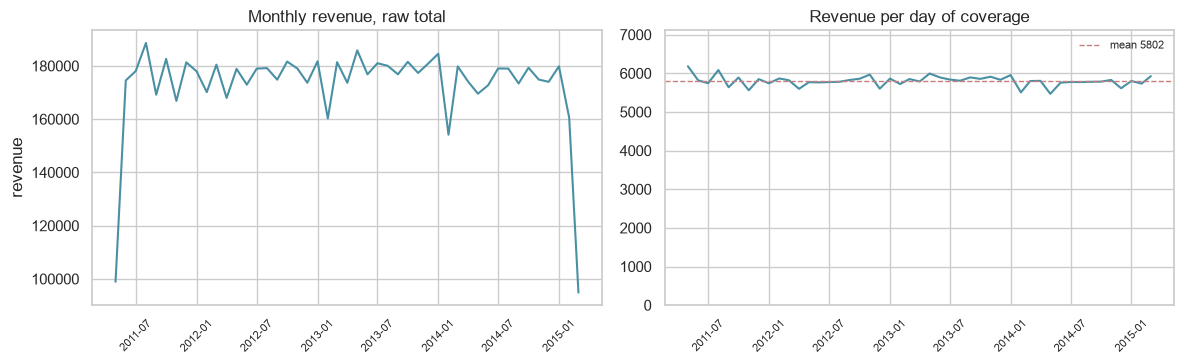

revenue per day: mean 5802  sd 133  CV 0.023
lowest  5470 (2014-05)
highest 6181 (2011-05)


In [18]:
monthly = main_data.groupby(main_data.trans_date.dt.to_period("M")).agg(
    revenue      = ("tran_amount", "sum"),
    transactions = ("tran_amount", "size"))

days = np.asarray(monthly.index.to_timestamp().days_in_month, dtype=float)
days[0]  = 16     # 16-31 May 2011
days[-1] = 16     # 1-16 Mar 2015
monthly["days"]        = days
monthly["rev_per_day"] = monthly.revenue / monthly.days

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
idx = monthly.index.to_timestamp()

ax[0].plot(idx, monthly.revenue, color="#4a90a4")
ax[0].set_title("Monthly revenue, raw total")
ax[0].set_ylabel("revenue")

ax[1].plot(idx, monthly.rev_per_day, color="#4a90a4")
ax[1].set_ylim(0, monthly.rev_per_day.max() * 1.15)
ax[1].axhline(monthly.rev_per_day.mean(), color="#c87f7f", ls="--", lw=1,
              label=f"mean {monthly.rev_per_day.mean():.0f}")
ax[1].set_title("Revenue per day of coverage")
ax[1].legend(frameon=False, fontsize=8)

for a in ax:
    a.tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout(); plt.show()

cv = monthly.rev_per_day.std() / monthly.rev_per_day.mean()
print(f"revenue per day: mean {monthly.rev_per_day.mean():.0f}  "
      f"sd {monthly.rev_per_day.std():.0f}  CV {cv:.3f}")
print(f"lowest  {monthly.rev_per_day.min():.0f} ({monthly.rev_per_day.idxmin()})")
print(f"highest {monthly.rev_per_day.max():.0f} ({monthly.rev_per_day.idxmax()})")

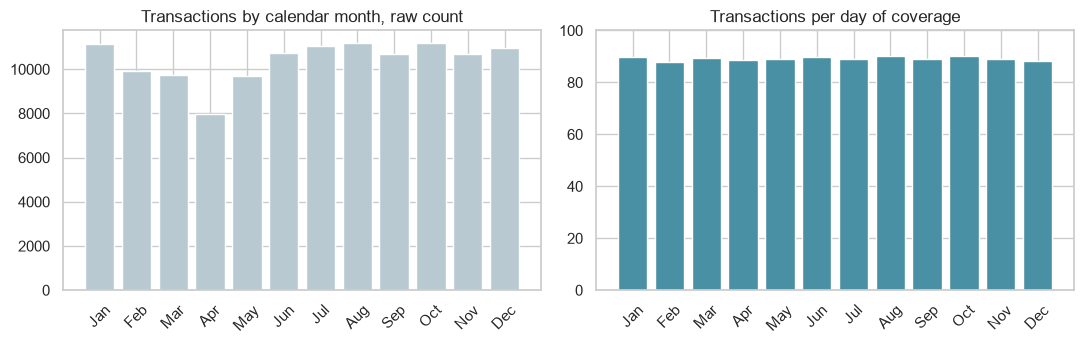

     transactions  times_in_file  days_covered  txn_per_day
Jan         11144              4           124         89.9
Feb          9937              4           113         87.9
Mar          9751              4           109         89.5
Apr          7973              3            90         88.6
May          9688              4           109         88.9
Jun         10756              4           120         89.6
Jul         11033              4           124         89.0
Aug         11195              4           124         90.3
Sep         10685              4           120         89.0
Oct         11175              4           124         90.1
Nov         10669              4           120         88.9
Dec         10963              4           124         88.4


In [19]:
# Is there a seasonal pattern by calendar month?
by_month = pd.DataFrame({
    "transactions": main_data.groupby(main_data.trans_date.dt.month).size(),
    "times_in_file": main_data.groupby([main_data.trans_date.dt.month,
                                        main_data.trans_date.dt.year]).size()
                     .groupby(level=0).size(),
    "days_covered": main_data.groupby([main_data.trans_date.dt.month,
                                       main_data.trans_date.dt.year])["trans_date"]
                    .nunique().groupby(level=0).sum(),
})
by_month["txn_per_day"] = (by_month.transactions / by_month.days_covered).round(1)
by_month.index = ["Jan","Feb","Mar","Apr","May","Jun",
                  "Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(by_month.index, by_month.transactions, color="#b8c9d1")
ax[0].set_title("Transactions by calendar month, raw count")
ax[0].tick_params(axis="x", rotation=45)

ax[1].bar(by_month.index, by_month.txn_per_day, color="#4a90a4")
ax[1].set_ylim(0, 100)
ax[1].set_title("Transactions per day of coverage")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

print(by_month.to_string())

### Conclusion
 
**There is no trend, no seasonality and no volatility in this dataset.**
 
Revenue per day holds at 5,802 with a standard deviation of 133 across 47
months, a coefficient of variation of 2.3%. The lowest month is 5,470 and the
highest 6,181. The raw chart on the left looks volatile and the normalised chart
on the right is flat, and the difference between them is entirely month length.
 
The same applies by calendar month. On raw counts August appears to peak at
11,195 and April to trough at 7,973. But April falls inside the file three times
while most months fall inside it four times. Per day of coverage every month
sits between 87.9 and 90.3, a spread of under 3%.
 
The apparent collapse at the right-hand end of the raw series is the file ending
on 16 March 2015.
 
Any planning built on a seasonal pattern in this data would be planning around
the calendar rather than around customer behaviour.
 

## 11. Purchase cadence

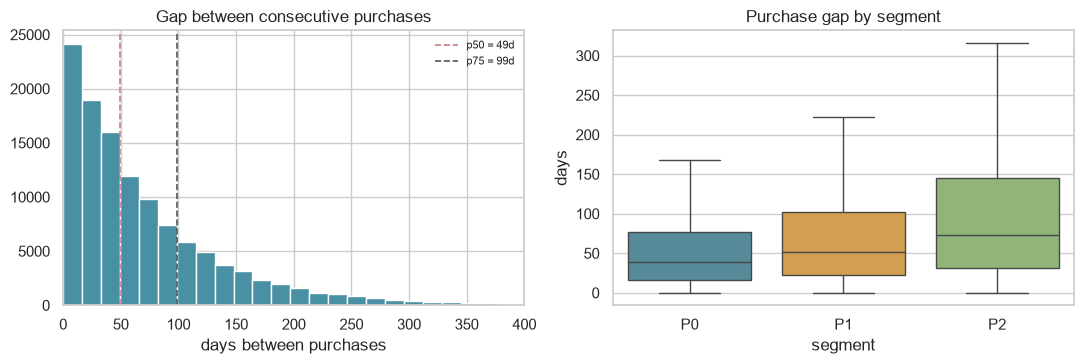

mean 72.37   median 49   p75 99   p90 167   max 985

           mean  median
segment               
P0        55.0    39.0
P1        72.9    52.0
P2       104.3    73.0


In [20]:
d = main_data.sort_values(["customer_id", "trans_date"]).copy()
d["gap_days"] = d.groupby("customer_id")["trans_date"].diff().dt.days
d = d.merge(customers[["customer_id", "segment"]], on="customer_id")
gaps = d["gap_days"].dropna()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

ax[0].hist(gaps, bins=60, color="#4a90a4")
for q, c in [(.5, "#c87f7f"), (.75, "#555555")]:
    v = gaps.quantile(q)
    ax[0].axvline(v, color=c, ls="--", lw=1.2, label=f"p{int(q*100)} = {v:.0f}d")
ax[0].set_xlim(0, 400); ax[0].set_xlabel("days between purchases")
ax[0].set_title("Gap between consecutive purchases"); ax[0].legend(frameon=False, fontsize=8)

sns.boxplot(data=d.dropna(subset=["gap_days"]), x="segment", y="gap_days",
            order=["P0", "P1", "P2"], hue="segment", legend=False,
            palette=PALETTE, showfliers=False, ax=ax[1])
ax[1].set_title("Purchase gap by segment"); ax[1].set_ylabel("days")

plt.tight_layout(); plt.show()

print(f"mean {gaps.mean():.2f}   median {gaps.median():.0f}   "
      f"p75 {gaps.quantile(.75):.0f}   p90 {gaps.quantile(.9):.0f}   max {gaps.max():.0f}")
print("\n", d.groupby("segment").gap_days.agg(["mean", "median"]).round(1).to_string())

### Conclusion
 
The median gap between purchases is 49 days, the 75th percentile is 99 days and
the 90th is 167. The mean of 72 is pulled up by a long right tail, so the median
is the figure to quote.
 
By segment: P0 returns in 55 days on average, P1 in 73, P2 in 104.
 
**A practical consequence: 75% of repeat purchases happen within 99 days of the
previous one**, so a customer who has not bought in that long sits outside normal
behaviour for this base. That makes 99 days a defensible reactivation trigger,
and the per-segment figures argue for setting it separately by segment rather
than globally.
 
It also means a one-month window is too short to judge whether a customer is
active. A customer buying at a perfectly normal 49-day cadence will be absent in
roughly half of all calendar months.
 

## 12. Cohort retention analysis

Every section so far groups customers by what they are worth. None of them
groups customers by **when they arrived**, which is the one question this
dataset has the span to answer: four years of history is long enough to follow
a group of customers for several years after they first appear.

**What this adds that RFM and segmentation cannot.** RFM scores every customer
as of a single date, so it says who is valuable now and nothing about how they
got there. It also cannot separate a customer who buys every three weeks and is
two weeks overdue from one who bought once and will never return, because it has
no tenure axis. A cohort analysis holds tenure constant and compares groups at
the same age, which is what makes it a controlled comparison rather than a
snapshot.

**The method.** Two columns do the whole job:
 
- `cohort` — the period containing a customer's first purchase. Fixed, never
  changes.
- `period_index` — how many whole periods elapsed between that cohort and the
  period of a given transaction. Zero for transactions in the cohort period
  itself.


Once those exist, a retention triangle is a pivot table. The hard part of cohort
analysis is never the pivot; it is knowing whether the cohort dates mean
anything, which is what the diagnostics below are for.
 
**Period length.** Section 11 found a median gap of 49 days and a 75th
percentile of 99 days. A calendar month is shorter than the median, so on a
monthly grid a customer buying at a perfectly normal cadence is absent from
roughly half of all months by construction. A quarter is 91 days, just under the
75th percentile, so a customer at or better than normal cadence appears in
essentially every quarter. The grid below is quarterly for that reason, and the
monthly version is computed afterwards to show the difference.
 

In [23]:
def add_cohort_columns(df, freq="Q"):
    """Attach `cohort` and `period_index` to transaction rows."""
    d = df.copy()
    d["order_period"] = d["trans_date"].dt.to_period(freq)

    # transform("min") broadcasts each customer's first purchase back onto all
    # of their rows. agg() would collapse to one row per customer and need a
    # merge back.
    first = d.groupby("customer_id")["trans_date"].transform("min")
    d["cohort"] = first.dt.to_period(freq)

    # Whole-period arithmetic on Periods. Using (date - date).days // 30 would
    # drift, and by period 40 it would be off by more than a whole period.
    if freq == "Q":
        d["period_index"] = ((d.order_period.dt.year  - d.cohort.dt.year) * 4
                             + (d.order_period.dt.quarter - d.cohort.dt.quarter))
    else:
        d["period_index"] = ((d.order_period.dt.year  - d.cohort.dt.year) * 12
                             + (d.order_period.dt.month   - d.cohort.dt.month))
    return d


# Calendar periods the file only partly covers. A cohort grid spreads these
# down a DIAGONAL, not along one row: March 2015 is period 15 for the first
# cohort, 14 for the second, 13 for the third. Masking only the bottom row
# would miss almost all of it.
PARTIAL_Q = {DATA_START.to_period("Q"), DATA_END.to_period("Q")}
PARTIAL_M = {DATA_START.to_period("M"), DATA_END.to_period("M")}


def cohort_matrix(df, freq="Q", metric="retention", min_cohort_size=100):
    """Return (matrix, cohort_sizes) with partially-covered cells blanked."""
    d = add_cohort_columns(df, freq)

    sizes = d.groupby("cohort")["customer_id"].nunique()
    keep  = sizes[sizes >= min_cohort_size].index      # drop cohorts too small to read
    d, sizes = d[d.cohort.isin(keep)], sizes.loc[keep]

    g = (d.groupby(["cohort", "period_index"])
           .agg(actives=("customer_id", "nunique"), revenue=("tran_amount", "sum"))
           .reset_index())

    if metric == "retention":
        g["value"] = g.actives / g.cohort.map(sizes)
    else:                                              # revenue per active customer
        g["value"] = g.revenue / g.actives

    mat = g.pivot(index="cohort", columns="period_index", values="value")

    partial = PARTIAL_Q if freq == "Q" else PARTIAL_M
    for c in mat.index:
        for k in mat.columns:
            if (c + k) in partial:
                mat.loc[c, k] = np.nan
    return mat, sizes


acquisition = (customers.first_purchase.dt.to_period("M")
               .value_counts().sort_index())
print(f"monthly cohorts: {len(acquisition)}")
print(acquisition.head(12).to_string())
print(f"\ncustomers first appearing in 2013 or later: "
      f"{acquisition[acquisition.index >= '2013-01'].sum()}")

monthly cohorts: 28
first_purchase
2011-05    1343
2011-06    1804
2011-07    1214
2011-08     862
2011-09     467
2011-10     379
2011-11     242
2011-12     187
2012-01     105
2012-02      72
2012-03      60
2012-04      36
Freq: M

customers first appearing in 2013 or later: 12


### Before trusting any triangle
 
The acquisition curve is the first thing to look at, and it does not look like
acquisition. It runs 1,343, 1,804, 1,214, 862, 467, 379, 242, 187, 105, 72, 60,
36 and keeps falling, with **12 customers in total first appearing from 2013
onwards** out of 6,884.
 
A real business keeps acquiring. A smooth geometric decay to nothing is the
signature of a file that opened on a customer base that already existed, where
"first purchase in the file" means the first time an existing customer happened
to show up rather than the date they became a customer. That is **left
censoring**, and it would make every cohort here contaminated.
 
The curve alone is suggestive rather than conclusive, so the next cell tests it
properly.
 

In [24]:
# --- the exponential arrival test ---------------------------------------
# Gaps BETWEEN consecutive purchases are never censored: both ends are
# observed. So estimate each customer's purchase rate from their own internal
# gaps, then ask a counterfactual question with no fitted parameters:
#
#   if all 6,884 customers already existed on day 1, how many would first
#   be SEEN in month 1, month 2, and so on?
#
# For a customer buying at rate lambda, P(not yet seen by day t) = exp(-lambda*t).
# Summing across customers gives the expected number still unseen, and the
# differences give expected first appearances per month.

d = main_data.sort_values(["customer_id", "trans_date"]).copy()
d["gap"] = d.groupby("customer_id")["trans_date"].diff().dt.days
lam = (1 / d.groupby("customer_id")["gap"].mean()).dropna()      # purchases per day

edges   = pd.period_range(DATA_START.to_period("M"), periods=14, freq="M")
elapsed = [(min(p.end_time.normalize(), DATA_END) - DATA_START).days + 1 for p in edges]
still_unseen = [np.exp(-lam * t).sum() for t in elapsed]
predicted    = -np.diff(np.concatenate([[len(lam)], still_unseen]))
observed     = acquisition.reindex(edges, fill_value=0).values

arrival = pd.DataFrame({"cohort": [str(p) for p in edges],
                        "days_elapsed": elapsed,
                        "observed_new": observed,
                        "predicted_if_all_pre_existing": predicted.round(0).astype(int)})
arrival["ratio"] = (arrival.observed_new /
                    arrival.predicted_if_all_pre_existing).round(2)
print(arrival.to_string(index=False))
print(f"\ntotals over 14 months: observed {observed.sum():,}  "
      f"predicted {int(predicted.sum()):,}")

 cohort  days_elapsed  observed_new  predicted_if_all_pre_existing  ratio
2011-05            16          1343                           1352   0.99
2011-06            46          1804                           1823   0.99
2011-07            77          1214                           1221   0.99
2011-08           108           862                            796   1.08
2011-09           138           467                            512   0.91
2011-10           169           379                            357   1.06
2011-11           199           242                            235   1.03
2011-12           230           187                            168   1.11
2012-01           261           105                            116   0.91
2012-02           290            72                             77   0.94
2012-03           321            60                             59   1.02
2012-04           351            36                             41   0.88
2012-05           382            27   

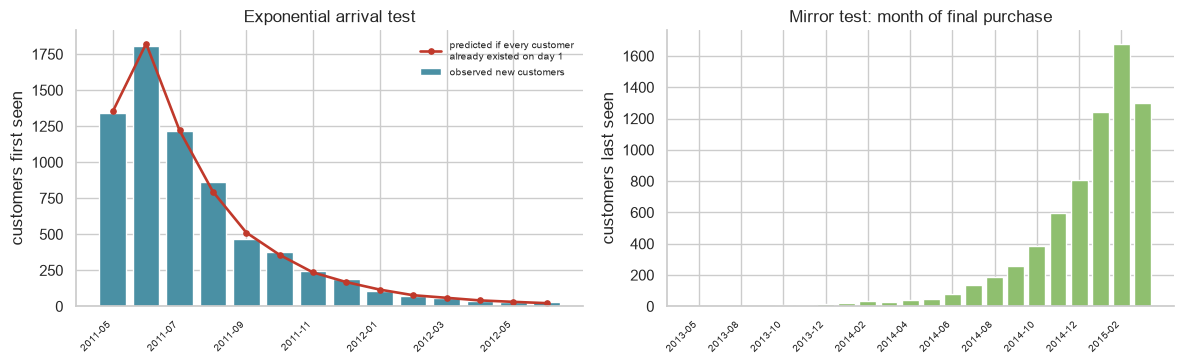

customers whose last purchase falls before 2014: 38
customers whose last purchase falls in Jan-Mar 2015: 4,225 (61.4%)

          customers  purchases_per_exposed_month
coh                                            
2011-05       1343                        0.427
2011-06       1804                        0.418
2011-07       1214                        0.426
2011-08        862                        0.413
2011-09        467                        0.417
2011-10        379                        0.419
2011-11        242                        0.410
2011-12        187                        0.405
2012-01        105                        0.375
2012-02         72                        0.380


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))

x = np.arange(len(arrival))
ax[0].bar(x, arrival.observed_new, color="#4a90a4", label="observed new customers")
ax[0].plot(x, arrival.predicted_if_all_pre_existing, color="#c0392b", lw=1.9,
           marker="o", ms=3.8,
           label="predicted if every customer\nalready existed on day 1")
ax[0].set_xticks(x[::2]); ax[0].set_xticklabels(arrival.cohort[::2], rotation=45,
                                                ha="right", fontsize=7.5)
ax[0].set_ylabel("customers first seen")
ax[0].set_title("Exponential arrival test")
ax[0].legend(frameon=False, fontsize=7.5)

# mirror test: if lapses mirror arrivals, the panel is closed at both ends
lapse = customers.last_purchase.dt.to_period("M").value_counts().sort_index()
ax[1].bar(range(len(lapse)), lapse.values, color="#8fbf6f")
step = max(1, len(lapse)//8)
ax[1].set_xticks(range(0, len(lapse), step))
ax[1].set_xticklabels([str(p) for p in lapse.index[::step]], rotation=45,
                      ha="right", fontsize=7.5)
ax[1].set_ylabel("customers last seen")
ax[1].set_title("Mirror test: month of final purchase")

for a in ax:
    for s in ("top", "right"): a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

print(f"customers whose last purchase falls before 2014: "
      f"{(customers.last_purchase < '2014-01-01').sum()}")
print(f"customers whose last purchase falls in Jan-Mar 2015: "
      f"{(customers.last_purchase >= '2015-01-01').sum():,} "
      f"({(customers.last_purchase >= '2015-01-01').mean():.1%})")

# third check: do later cohorts behave like genuinely newer customers?
rate_by_cohort = (customers.assign(
        coh=customers.first_purchase.dt.to_period("M"),
        rate=customers.frequency / (customers.tenure_days / 30.44).clip(lower=1))
    .groupby("coh").agg(customers=("customer_id", "size"),
                        purchases_per_exposed_month=("rate", "mean")).round(3))
print("\n", rate_by_cohort.head(10).to_string())

### What the diagnostics show
 
**The arrival test settles it.** Over the first fourteen months the model
predicts 6,810 first appearances and 6,826 are observed. Month by month the
ratio stays between 0.87 and 1.27, with the three largest months at 0.99.
 
A model whose only assumption is *every customer already existed before the file
opened* reproduces the acquisition curve almost exactly, with no fitted
parameters. These are not acquisition cohorts. They are arrival times of an
already-active customer base, sorted by how often each customer happens to buy.
 
Two confirmations:
 
- **The mirror test.** Only 38 customers in 6,884 make their final purchase
  before 2014, and 61.4% have theirs in the last three months of the file. The
  lapse distribution mirrors the arrival distribution, so the panel is closed at
  both ends. There is no churn here either, only right censoring.
- **Purchase rate by cohort.** Transactions per month of exposure run 0.427,
  0.418, 0.426, 0.413 across the 2011 cohorts and 0.375 to 0.380 for 2012. No
  ramp-up and no difference in kind. The customers who "arrive" later are slower
  buyers who took longer to surface, not newer customers.
**The standard fix, and why it fails here.** The usual remedy for left censoring
is a washout period: discard every cohort formed inside the first W months,
where W is long enough that any pre-existing customer would almost certainly
have transacted at least once. A common rule is three to four times the typical
gap. The 90th percentile gap here is 167 days, so W would need to be fifteen to
eighteen months, which leaves cohorts of 9, 5, 2, 2 and 1 customers. The fix is
correct and this data does not survive it.
 
The second standard fix is to stop using first transaction as a proxy and use a
real signup date from another table. There isn't one.
 
The triangles below are therefore built and read as a demonstration of method,
with the censoring stated rather than worked around.
 

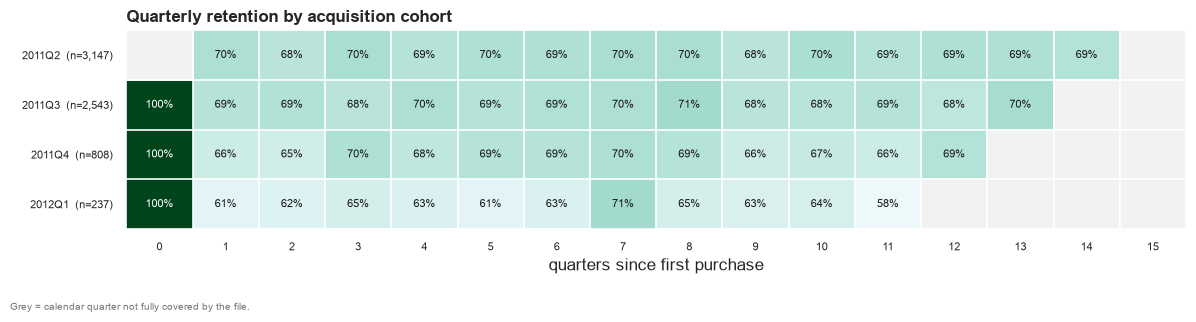

period_index     0     1     2     3     4     5     6     7     8     9     10    11    12    13    14  15
cohort                                                                                                     
2011Q2          NaN  69.7  68.4  70.0  68.6  69.5  69.4  70.0  70.0  68.4  69.9  68.6  69.5  69.4  69.0 NaN
2011Q3        100.0  68.5  69.2  68.2  69.7  68.6  69.4  69.6  70.8  68.3  68.4  68.9  68.0  70.4   NaN NaN
2011Q4        100.0  66.2  65.2  69.6  67.6  68.8  68.8  69.7  68.6  65.8  66.8  66.2  69.1   NaN   NaN NaN
2012Q1        100.0  61.2  62.4  64.6  62.9  61.2  62.9  70.9  64.6  63.3  64.1  58.2   NaN   NaN   NaN NaN


In [26]:
ret_q, sizes_q = cohort_matrix(main_data, freq="Q", metric="retention",
                               min_cohort_size=100)

fig, ax = plt.subplots(figsize=(12, 3.0))
vals = ret_q.values.astype(float)
im = ax.imshow(vals, cmap="BuGn", aspect="auto", vmin=0.55, vmax=1.0)

for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        if np.isnan(v):
            ax.add_patch(plt.Rectangle((j-.5, i-.5), 1, 1, facecolor="#f2f2f2",
                                       edgecolor="white", lw=1.2))
        else:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.6,
                    color="white" if v > 0.9 else "#1a1a1a")

ax.set_xticks(range(vals.shape[1])); ax.set_xticklabels(ret_q.columns, fontsize=8)
ax.set_yticks(range(vals.shape[0]))
ax.set_yticklabels([f"{c}  (n={sizes_q[c]:,})" for c in ret_q.index], fontsize=8)
ax.set_xlabel("quarters since first purchase")
ax.set_title("Quarterly retention by acquisition cohort", fontweight="bold", loc="left")
ax.grid(False)                      # seaborn's whitegrid draws over the cells
ax.set_xticks(np.arange(-.5, vals.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, vals.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", lw=1.2); ax.tick_params(which="minor", length=0)
for s in ax.spines.values(): s.set_visible(False)
fig.text(0.005, -0.06, "Grey = calendar quarter not fully covered by the file.",
         fontsize=7.4, color="#777")
plt.tight_layout(); plt.show()

print((ret_q * 100).round(1).to_string())

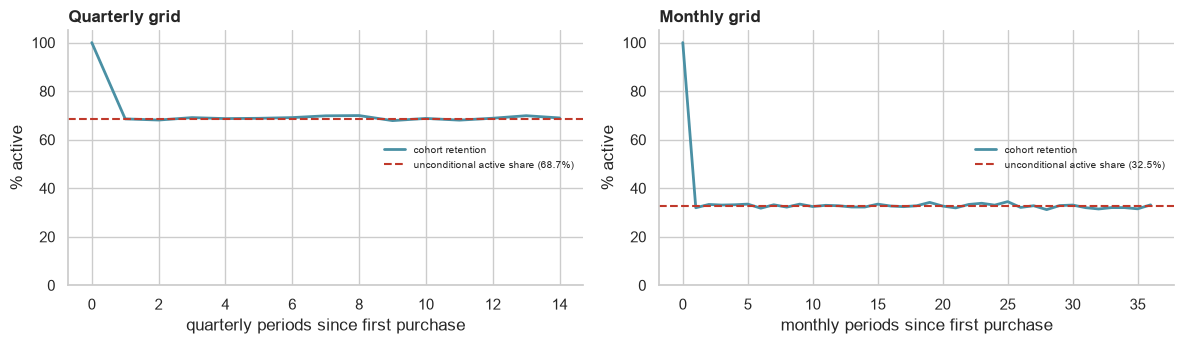

quarterly  cohort retention k>=1 : 68.9%   unconditional active: 68.7%
monthly    cohort retention k1-24: 32.8%   unconditional active: 32.5%
monthly curve range over k=1..24 : 31.8% to 34.1%


In [27]:
# A retention figure only means something next to the rate you would get by
# picking customers at random. If cohort retention equals the unconditional
# share of the base that is active, cohort membership carries no information.

def weighted_curve(mat, sizes):
    w = sizes.reindex(mat.index)
    return mat.mul(w, axis=0).sum(skipna=True) / mat.notna().mul(w, axis=0).sum()

ret_m, sizes_m = cohort_matrix(main_data, freq="M", metric="retention",
                               min_cohort_size=150)
curve_q, curve_m = weighted_curve(ret_q, sizes_q), weighted_curve(ret_m, sizes_m)

act_q = main_data.groupby(main_data.trans_date.dt.to_period("Q"))["customer_id"].nunique() / len(customers)
act_m = main_data.groupby(main_data.trans_date.dt.to_period("M"))["customer_id"].nunique() / len(customers)
base_q = act_q[[p for p in act_q.index if p not in PARTIAL_Q]].mean()
base_m = act_m[[p for p in act_m.index if p not in PARTIAL_M]].mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, curve, base, lbl, n in [
        (ax[0], curve_q, base_q, "quarterly", 15),
        (ax[1], curve_m, base_m, "monthly", 37)]:
    k = curve.index[:n]
    a.plot(k, curve.iloc[:n] * 100, color="#4a90a4", lw=2, label="cohort retention")
    a.axhline(base * 100, color="#c0392b", ls="--", lw=1.5,
              label=f"unconditional active share ({base:.1%})")
    a.set_ylim(0, 105); a.set_ylabel("% active")
    a.set_xlabel(f"{lbl} periods since first purchase")
    a.set_title(f"{lbl.capitalize()} grid", fontweight="bold", loc="left")
    a.legend(frameon=False, fontsize=7.5, loc="center right")
    for s in ("top", "right"): a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

print(f"quarterly  cohort retention k>=1 : {curve_q[1:].mean():.1%}   "
      f"unconditional active: {base_q:.1%}")
print(f"monthly    cohort retention k1-24: {curve_m[1:25].mean():.1%}   "
      f"unconditional active: {base_m:.1%}")
print(f"monthly curve range over k=1..24 : "
      f"{curve_m[1:25].min():.1%} to {curve_m[1:25].max():.1%}")

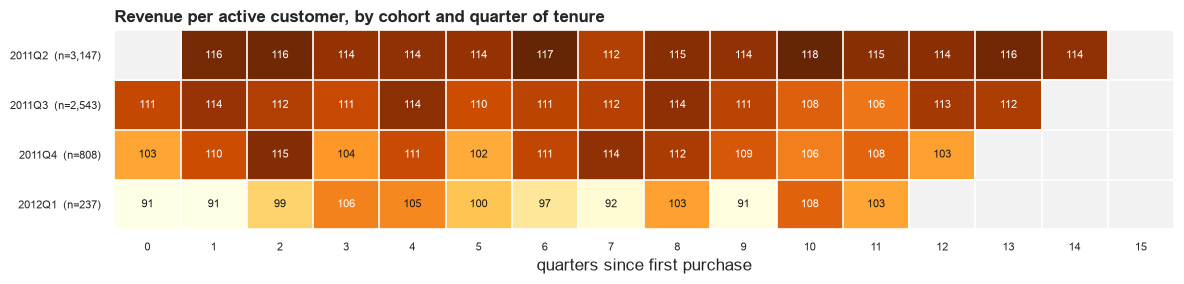

period_index     0      1      2      3      4      5      6      7      8      9      10     11     12     13     14  15
cohort                                                                                                                   
2011Q2          NaN  115.8  116.0  113.9  114.2  113.9  116.9  111.9  114.6  113.9  118.4  114.5  114.5  116.0  114.2 NaN
2011Q3        110.7  113.6  112.0  110.5  114.3  110.3  111.3  111.7  114.2  111.4  108.4  106.4  112.8  112.3    NaN NaN
2011Q4        102.8  110.3  114.9  103.9  110.5  102.4  111.0  114.1  112.4  109.2  105.8  108.0  103.2    NaN    NaN NaN
2012Q1         90.6   90.7   99.0  105.7  105.0  100.3   96.5   92.1  103.2   91.4  108.2  102.8    NaN    NaN    NaN NaN

why the rows differ - average basket and purchases by cohort quarter:
        customers  avg_basket  avg_purchases
cq                                          
2011Q2       3147       64.60          19.13
2011Q3       2543       62.99          18.17
2011Q4        808

In [28]:
# Second view: revenue per SURVIVING customer. Spend in the period divided by
# the customers actually active in it, not by the original cohort size, so
# retention and spend are separated rather than folded into one number.
rev_q, _ = cohort_matrix(main_data, freq="Q", metric="rev_per_active",
                         min_cohort_size=100)

fig, ax = plt.subplots(figsize=(12, 3.0))
vals = rev_q.values.astype(float)
lo, hi = np.nanpercentile(vals, 2), np.nanpercentile(vals, 98)
im = ax.imshow(vals, cmap="YlOrBr", aspect="auto", vmin=lo, vmax=hi)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        if np.isnan(v):
            ax.add_patch(plt.Rectangle((j-.5, i-.5), 1, 1, facecolor="#f2f2f2",
                                       edgecolor="white", lw=1.2))
        else:
            # pick text colour from position on the COLOUR SCALE, not from a
            # percentile of the values, so dark cells always get light text
            shade = (v - lo) / (hi - lo + 1e-9)
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.6,
                    color="white" if shade > 0.55 else "#1a1a1a")
ax.set_xticks(range(vals.shape[1])); ax.set_xticklabels(rev_q.columns, fontsize=8)
ax.set_yticks(range(vals.shape[0]))
ax.set_yticklabels([f"{c}  (n={sizes_q[c]:,})" for c in rev_q.index], fontsize=8)
ax.set_xlabel("quarters since first purchase")
ax.set_title("Revenue per active customer, by cohort and quarter of tenure",
             fontweight="bold", loc="left")
ax.grid(False)                      # seaborn's whitegrid draws over the cells
ax.set_xticks(np.arange(-.5, vals.shape[1], 1), minor=True)
ax.set_yticks(np.arange(-.5, vals.shape[0], 1), minor=True)
ax.grid(which="minor", color="white", lw=1.2); ax.tick_params(which="minor", length=0)
for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.show()

print(rev_q.round(1).to_string())
print("\nwhy the rows differ - average basket and purchases by cohort quarter:")
print(customers.assign(cq=customers.first_purchase.dt.to_period("Q"))
      .groupby("cq").agg(customers=("customer_id", "size"),
                         avg_basket=("aov", "mean"),
                         avg_purchases=("frequency", "mean")).head(5).round(2).to_string())

### Conclusion
 
**Retention is flat, and it sits exactly on the base rate.** Size-weighted
cohort retention from the first quarter onward averages 68.9%, against an
unconditional 68.7% of the whole base active in any full quarter. On the monthly
grid it is 32.8% against 32.5%, varying only between 31.8% and 34.1% across
twenty-four periods.
 
Knowing which cohort a customer belongs to, and how long they have been a
customer, tells you nothing about whether they buy this quarter. A retention
curve that collapses onto the base rate is the clearest way to say that, and it
is a stronger statement than showing a flat heatmap and hoping nobody asks.
 
**Revenue per active customer is flat within each cohort** — the 2011Q3 row runs
111 to 114 across fourteen quarters — and the only real variation is between
rows, from 114 in 2011Q2 down to 91 in 2012Q1. That is not a tenure effect. It
is the slow-buyer selection from the arrival test showing up again: later
"cohorts" have a lower average basket (64.60 down to 57.10) and fewer purchases
(19.13 down to 14.06) because they were low-frequency customers all along, which
is precisely why they surfaced later.
 
**This also answers the loose thread from Section 4.** The tenure-to-frequency
correlation of 0.292 is not early customers being more valuable. It is the
observation window: a high-frequency customer appears sooner simply by buying
sooner, so appearing early and buying often are the same fact measured twice.
 
**What this contributes to the overall picture.** Sections 10 and 11 showed the
data is flat over time. This section shows something structurally stronger: there
is no acquisition and no churn. The customer base is fixed, closed at both ends,
and every customer is present throughout. No real retailer's data behaves that
way, and it is the firmest evidence in the notebook that this dataset is
generated rather than observed.
 
**Two things worth stating about method.** The partial-period masking spreads
down a diagonal rather than along a row, because a partial calendar quarter is
period 15 for the first cohort and period 12 for the fourth; masking only the
last row would have left most of it in place. And cohorts below 100 customers
are excluded, because the 2012Q2 cohort onwards holds fewer than 100 people and
a single customer moves those percentages by more than a point.
 

## 13. Conclusion and limitations

### What the analysis found
 
Customers divide into three spending tiers, though the underlying data is a
continuum rather than separable groups, so the tiers are a chosen banding. P0 is
27.7% of customers and 40.5% of revenue.
 
The campaign is worth targeting. P0 contains 50.9% of responders while being
27.7% of the base, a lift of 1.84x, and P2 returns 0.23x. Restricting contact to
P0 reaches half the responders at roughly a quarter of the cost.
 
Segment and response are related but modestly, with Cramér's V at 0.197.
Frequency is the dimension that separates response; recency runs backwards
against it.
 
Purchase cadence gives the one operationally useful number: 75% of repeat
purchases fall within 99 days, which sets a reactivation trigger.
 
Cohort retention is flat and sits on the base rate: 68.9% against an
unconditional 68.7% quarterly. Cohort membership and tenure carry no
information about whether a customer buys in a given period.
 
Sales show no trend, no seasonality and no volatility once monthly figures are
divided by days covered. Revenue per day holds at 5,802 with a 2.3% coefficient
of variation across 47 months.
 
### The most important finding
 
**That flatness is itself the result.** A real retailer gains and loses
customers, has busy and quiet periods, and shows some drift in average basket
size. This dataset has none of them. Revenue per day is constant to within
2.3%, every calendar month falls between 87.9 and 90.3 transactions per day, and
average transaction value moves between 64.89 and 65.23 across five years.
 
Section 12 makes the case structurally rather than by flatness: there is no
acquisition and no churn. An arrival model assuming every customer already
existed before the file opened predicts 6,810 first appearances against 6,826
observed, and only 38 customers in 6,884 stop buying before 2014. The base is
fixed and closed at both ends.
 
Taken with the recency reversal in Section 5, this indicates the data is
generated rather than observed. The work here therefore demonstrates method
rather than describing a real business, and the recommendations below are framed
as what the analysis would support if the data were real.
 
### Recommendations
 
- **Contact P0 first.** 27.7% of the base, 50.9% of responders, 1.84x lift.
- **Exclude P2 from broad mailings.** 30.1% of the base, 7.0% of responders,
  0.23x lift. At equal cost per contact it returns less than a quarter of average.
- **Set the reactivation trigger at 99 days**, adjusted per segment: P0 returns
  in 55 days normally, P2 in 104, so a single global threshold would misfire on
  both.
- **Do not plan around seasonality.** There is none in this data.
### Limitations
 
- **The dataset appears to be generated, not observed.** Findings demonstrate
  method rather than describing a business.
- **The segments are a banding, not a discovery.** Frequency and monetary
  correlate at 0.93, PC1 carries 96.7% of variance, and silhouette has no peak.
  k=3 is a convention.
- **Both end months are partial**, covering 16 days each. Every monthly figure
  requires normalising by days covered.
- **The campaign response flag has no date.** One static value per customer, so
  response cannot be tracked over time or attributed to a specific campaign.
- **Recency behaves backwards against response**, the opposite of what RFM
  practice assumes. Reported rather than explained away.
- **The 12-month value estimate contains no churn term.** It assumes customers
  continue at their observed purchase rate.
- **The acquisition cohorts are fully left-censored.** Not merely the early
  ones: first-transaction date is the arrival time of an already-active
  customer, which the arrival test in Section 12 demonstrates with no fitted
  parameters. The standard washout fix would leave cohorts of fewer than ten
  customers, so it is stated rather than applied.
- **The far end is right-censored for the same reason.** Any survival or
  lifetime estimate from this data measures the observation window rather than
  customer behaviour.
- **No causal claims are supported.** Segment membership is derived from the same
  purchase behaviour it is then used to describe.
- **No currency or unit is given** in the source data.
### Further work
 
Cohort retention split by campaign response would connect Section 12 to the
hypothesis testing: whether responders retain differently from non-responders.
On this data it would show nothing, for the reasons set out above, but it is the
next question the analysis invites.
 
The method in Section 12 is worth re-running on a dataset with genuine
acquisition. Every diagnostic there — the arrival test, the mirror test, the
base-rate comparison — is reusable, and on real data they would separate a
retention problem from an acquisition problem rather than exposing a generated
file.

In [29]:
# Export for the SQL stage.
overall_data = main_data.merge(
    customers[["customer_id", "segment", "frequency", "monetary", "aov",
               "recency_days", "tenure_days", "clv_12m",
               "R", "F", "M", "RFM_score", "RFM_total", "rfm_tier"]],
    on="customer_id", how="left")
 
overall_data.to_csv(r"D:\Ongoing course\Projects\Retail sales analysis(Internship Studio)\Version 2\Derived data\overall_data.csv", index=False)
customers.to_csv(r"D:\Ongoing course\Projects\Retail sales analysis(Internship Studio)\Version 2\Derived data\customers.csv", index=False)
main_data.to_csv(r"D:\Ongoing course\Projects\Retail sales analysis(Internship Studio)\Version 2\Derived data\main_data.csv", index=False)
 
print("written:")
print(f"  main_data.csv    {len(main_data):>8,} rows - one per transaction")
print(f"  customers.csv    {len(customers):>8,} rows - one per customer")
print(f"  overall_data.csv {len(overall_data):>8,} rows - transactions joined to customer attributes")

written:
  main_data.csv     124,969 rows - one per transaction
  customers.csv       6,884 rows - one per customer
  overall_data.csv  124,969 rows - transactions joined to customer attributes
